# Robustness of O3 action advantages to future training masks

**Complete** · All fresh paired draws saved · 180/180 paired draws · ETA 0h 00m 00s  
Updated 2026-11-12T17:31:50.134862+01:00 · PID 20776

Each draw restores the saved MAE, AdamW and Lasso checkpoint. Skip, ¼× and 1× use the original initial training mask. All branches then train at ¼× on the same next 1,000 arrivals. Future training masks are identical across the three actions within each draw and fresh across draws. Scoring reuses the original measurement masks, bank schedule and 32-frame lookahead panels. The MAE augmentation is identity.

The study uses 18 checkpoints and 10 fresh draws per checkpoint. In the full run, each seed contributes the three highest apparent gains at +1,000 and three comparison checkpoints spread across the remaining gain ranks. These strata deliberately oversample apparent opportunities. All conclusions are conditional on the recorded future images and scoring masks.

## Does the original opportunity repeat?

| Selection group | Horizon | Checkpoints | Original deviations | Original gain | Fresh gain from original choices | Fresh draws above δ | Action signs reversed | Held-out draw gain |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | Largest apparent gains | 96 | 9 | 2 | +0.03247 | -0.00783 | 50.0% | 6/18 | +0.00135 | 
 | Largest apparent gains | 1000 | 9 | 9 | +0.46591 | -0.00414 | 41.1% | 18/18 | -0.04088 | 
 | Comparison | 96 | 9 | 0 | +0.00000 | +0.00000 | — | 7/18 | -0.00256 | 
 | Comparison | 1000 | 9 | 3 | +0.01123 | -0.00934 | 13.3% | 15/18 | -0.00677 | 

Positive gain favors deviation. The original policy chooses the best action in the saved draw only if its gain exceeds δ = 0.01 O3 units. That policy is frozen and scored on fresh draws. Fresh gains average checkpoint means, including zeros from default choices. The share above δ averages over checkpoints where the original policy deviated. Sign reversals count checkpoint–action pairs with both positive and negative advantage on fresh draws. Held-out draw gain chooses from the other fresh draws at that checkpoint and evaluates on the omitted draw. Live rows can contain different draw counts.


In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-mask-robustness')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


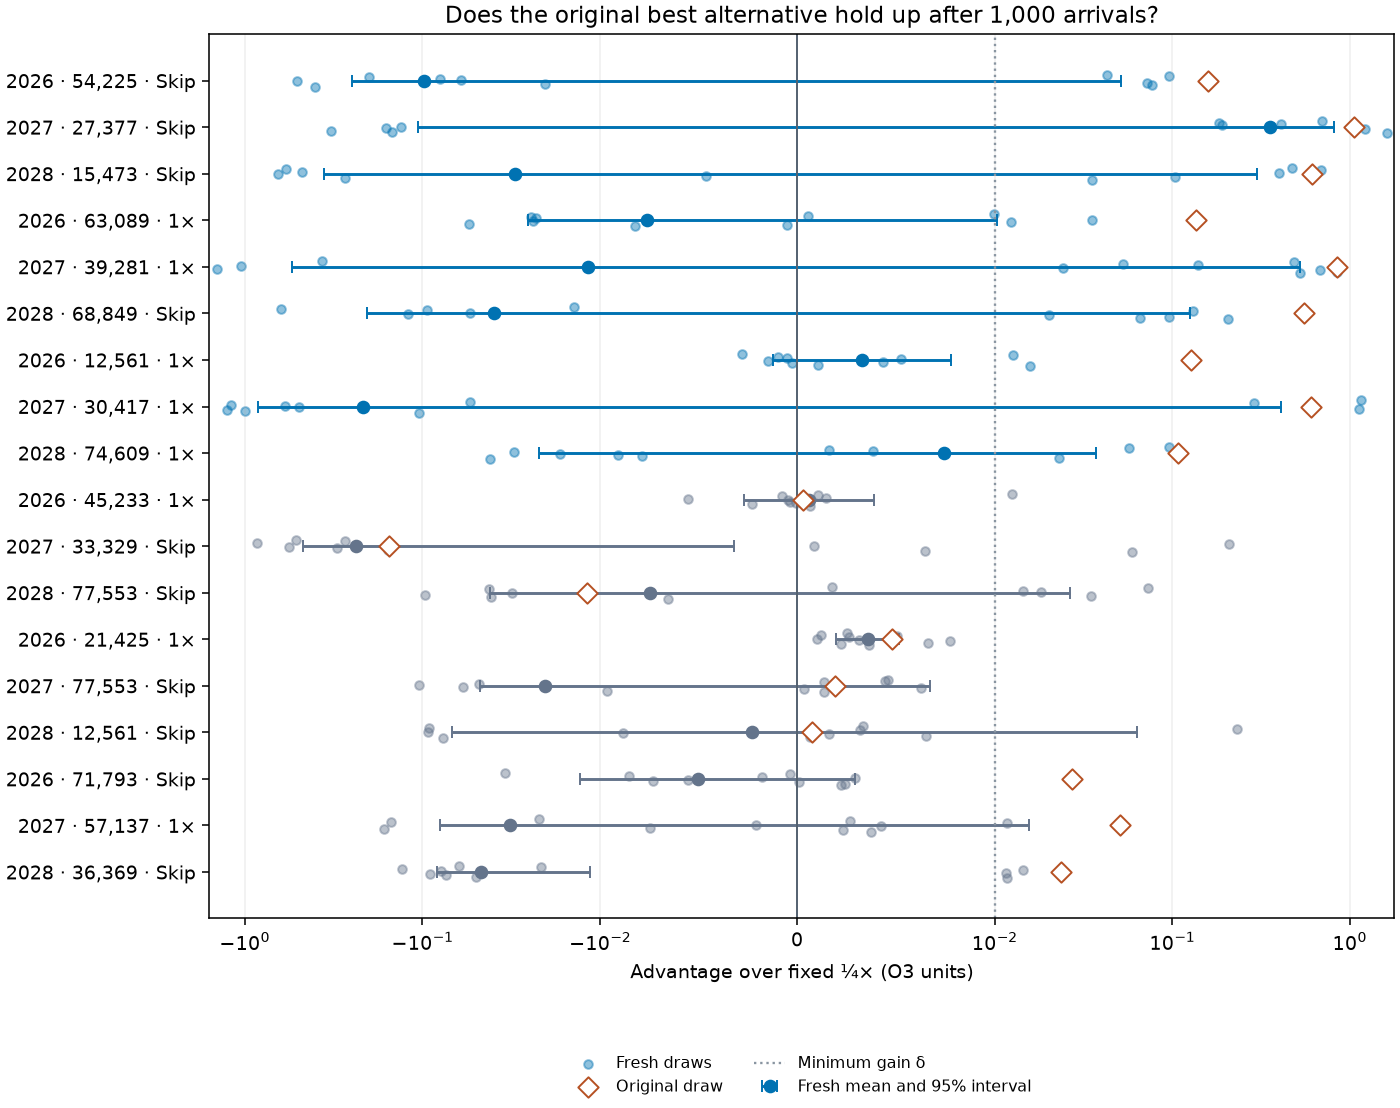

## Per-action stability

| Seed | Arrival | Horizon | Action | Draws | Original advantage | Fresh mean | 95% interval for mean | Fresh > 0 | Fresh > δ |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 2026 | 54225 | 96 | Skip | 10 | +0.00467 | +0.00400 | [+0.00304, +0.00496] | 100% | 0% | 
 | 2026 | 54225 | 96 | 1× | 10 | -0.03341 | -0.03150 | [-0.03586, -0.02714] | 0% | 0% | 
 | 2026 | 54225 | 1000 | Skip | 10 | +0.15873 | -0.09825 | [-0.24796, +0.05146] | 40% | 40% | 
 | 2026 | 54225 | 1000 | 1× | 10 | -0.12433 | -0.15742 | [-0.27146, -0.04339] | 30% | 10% | 
 | 2027 | 27377 | 96 | Skip | 10 | +0.00045 | -0.00003 | [-0.00049, +0.00043] | 40% | 0% | 
 | 2027 | 27377 | 96 | 1× | 10 | +0.00157 | +0.00327 | [+0.00264, +0.00390] | 100% | 0% | 
 | 2027 | 27377 | 1000 | Skip | 10 | +1.05573 | +0.35471 | [-0.10634, +0.81576] | 60% | 60% | 
 | 2027 | 27377 | 1000 | 1× | 10 | +0.82852 | -0.00659 | [-0.18722, +0.17405] | 40% | 40% | 
 | 2028 | 15473 | 96 | Skip | 10 | +0.21960 | +0.04949 | [-0.02708, +0.12606] | 70% | 70% | 
 | 2028 | 15473 | 96 | 1× | 10 | -0.12777 | +0.04732 | [-0.04237, +0.13702] | 80% | 50% | 
 | 2028 | 15473 | 1000 | Skip | 10 | +0.60775 | -0.03008 | [-0.36074, +0.30058] | 50% | 50% | 
 | 2028 | 15473 | 1000 | 1× | 10 | +0.03469 | -0.07273 | [-0.31909, +0.17363] | 60% | 60% | 
 | 2026 | 63089 | 96 | Skip | 10 | +0.00241 | +0.00142 | [+0.00072, +0.00211] | 100% | 0% | 
 | 2026 | 63089 | 96 | 1× | 10 | +0.00270 | +0.00322 | [+0.00267, +0.00378] | 100% | 0% | 
 | 2026 | 63089 | 1000 | Skip | 10 | +0.10596 | -0.00534 | [-0.02817, +0.01749] | 50% | 20% | 
 | 2026 | 63089 | 1000 | 1× | 10 | +0.13520 | -0.00763 | [-0.02558, +0.01032] | 40% | 20% | 
 | 2027 | 39281 | 96 | Skip | 10 | -0.10914 | -0.08263 | [-0.31186, +0.14661] | 50% | 30% | 
 | 2027 | 39281 | 96 | 1× | 10 | +0.07263 | -0.11996 | [-0.32198, +0.08206] | 40% | 30% | 
 | 2027 | 39281 | 1000 | Skip | 10 | +0.00649 | +0.00408 | [-0.42317, +0.43133] | 30% | 30% | 
 | 2027 | 39281 | 1000 | 1× | 10 | +0.84724 | -0.01165 | [-0.54386, +0.52057] | 70% | 70% | 
 | 2028 | 68849 | 96 | Skip | 10 | +0.00511 | +0.00493 | [+0.00459, +0.00527] | 100% | 0% | 
 | 2028 | 68849 | 96 | 1× | 10 | -0.01250 | -0.01270 | [-0.01333, -0.01207] | 0% | 0% | 
 | 2028 | 68849 | 1000 | Skip | 10 | +0.55050 | -0.03945 | [-0.20466, +0.12575] | 50% | 50% | 
 | 2028 | 68849 | 1000 | 1× | 10 | +0.40011 | -0.02875 | [-0.21301, +0.15552] | 50% | 40% | 
 | 2026 | 12561 | 96 | Skip | 10 | -0.00081 | -0.00092 | [-0.00110, -0.00075] | 0% | 0% | 
 | 2026 | 12561 | 96 | 1× | 10 | +0.00422 | +0.00444 | [+0.00414, +0.00473] | 100% | 0% | 
 | 2026 | 12561 | 1000 | Skip | 10 | -0.01108 | -0.01502 | [-0.03409, +0.00405] | 20% | 0% | 
 | 2026 | 12561 | 1000 | 1× | 10 | +0.12655 | +0.00329 | [-0.00122, +0.00780] | 50% | 20% | 
 | 2027 | 30417 | 96 | Skip | 10 | -0.00376 | -0.00386 | [-0.00402, -0.00370] | 0% | 0% | 
 | 2027 | 30417 | 96 | 1× | 10 | -0.02531 | -0.02043 | [-0.02287, -0.01799] | 0% | 0% | 
 | 2027 | 30417 | 1000 | Skip | 10 | +0.03608 | -0.25656 | [-0.62024, +0.10712] | 30% | 30% | 
 | 2027 | 30417 | 1000 | 1× | 10 | +0.60411 | -0.21564 | [-0.83858, +0.40731] | 30% | 30% | 
 | 2028 | 74609 | 96 | Skip | 10 | -0.00074 | -0.00180 | [-0.00243, -0.00116] | 0% | 0% | 
 | 2028 | 74609 | 96 | 1× | 10 | +0.00045 | +0.00077 | [+0.00011, +0.00143] | 70% | 0% | 
 | 2028 | 74609 | 1000 | Skip | 10 | +0.01252 | +0.00724 | [-0.02082, +0.03530] | 50% | 50% | 
 | 2028 | 74609 | 1000 | 1× | 10 | +0.10737 | +0.00744 | [-0.02217, +0.03704] | 50% | 30% | 
 | 2026 | 45233 | 96 | Skip | 10 | +0.00179 | +0.00223 | [+0.00138, +0.00308] | 100% | 0% | 
 | 2026 | 45233 | 96 | 1× | 10 | -0.00224 | -0.00311 | [-0.00568, -0.00055] | 0% | 0% | 
 | 2026 | 45233 | 1000 | Skip | 10 | -0.00044 | -0.00168 | [-0.00254, -0.00082] | 0% | 0% | 
 | 2026 | 45233 | 1000 | 1× | 10 | +0.00028 | +0.00060 | [-0.00271, +0.00390] | 40% | 10% | 
 | 2027 | 33329 | 96 | Skip | 10 | -0.11318 | -0.02156 | [-0.09102, +0.04790] | 50% | 30% | 
 | 2027 | 33329 | 96 | 1× | 10 | -0.14450 | -0.00923 | [-0.10212, +0.08365] | 30% | 20% | 
 | 2027 | 33329 | 1000 | Skip | 10 | -0.15448 | -0.23817 | [-0.47312, -0.00321] | 40% | 20% | 
 | 2027 | 33329 | 1000 | 1× | 10 | -0.32827 | -0.11434 | [-0.50003, +0.27135] | 40% | 40% | 
 | 2028 | 77553 | 96 | Skip | 10 | -0.00070 | -0.00026 | [-0.00111, +0.00060] | 30% | 0% | 
 | 2028 | 77553 | 96 | 1× | 10 | -0.00086 | -0.00122 | [-0.00407, +0.00163] | 40% | 0% | 
 | 2028 | 77553 | 1000 | Skip | 10 | -0.01189 | -0.00750 | [-0.04145, +0.02646] | 50% | 40% | 
 | 2028 | 77553 | 1000 | 1× | 10 | -0.02603 | +0.00042 | [-0.06554, +0.06639] | 30% | 30% | 
 | 2026 | 21425 | 96 | Skip | 10 | +0.00119 | +0.00189 | [+0.00134, +0.00243] | 100% | 0% | 
 | 2026 | 21425 | 96 | 1× | 10 | -0.00391 | -0.00468 | [-0.00507, -0.00429] | 0% | 0% | 
 | 2026 | 21425 | 1000 | Skip | 10 | -0.00307 | -0.00209 | [-0.00295, -0.00122] | 0% | 0% | 
 | 2026 | 21425 | 1000 | 1× | 10 | +0.00480 | +0.00356 | [+0.00196, +0.00516] | 100% | 0% | 
 | 2027 | 77553 | 96 | Skip | 10 | -0.00084 | -0.00020 | [-0.00042, +0.00002] | 30% | 0% | 
 | 2027 | 77553 | 96 | 1× | 10 | -0.00009 | -0.00066 | [-0.00116, -0.00016] | 10% | 0% | 
 | 2027 | 77553 | 1000 | Skip | 10 | +0.00188 | -0.02035 | [-0.04740, +0.00670] | 60% | 0% | 
 | 2027 | 77553 | 1000 | 1× | 10 | -0.00564 | +0.02628 | [-0.03150, +0.08406] | 50% | 30% | 
 | 2028 | 12561 | 96 | Skip | 10 | -0.00053 | -0.00050 | [-0.00063, -0.00037] | 0% | 0% | 
 | 2028 | 12561 | 96 | 1× | 10 | +0.00069 | +0.00071 | [+0.00055, +0.00087] | 100% | 0% | 
 | 2028 | 12561 | 1000 | Skip | 10 | +0.00073 | -0.00232 | [-0.06818, +0.06353] | 60% | 10% | 
 | 2028 | 12561 | 1000 | 1× | 10 | -0.00578 | +0.00556 | [-0.16953, +0.18064] | 40% | 30% | 
 | 2026 | 71793 | 96 | Skip | 10 | +0.00356 | +0.00459 | [+0.00328, +0.00590] | 100% | 0% | 
 | 2026 | 71793 | 96 | 1× | 10 | -0.00367 | -0.00410 | [-0.00498, -0.00322] | 0% | 0% | 
 | 2026 | 71793 | 1000 | Skip | 10 | +0.02706 | -0.00503 | [-0.01297, +0.00290] | 40% | 0% | 
 | 2026 | 71793 | 1000 | 1× | 10 | -0.02237 | +0.06827 | [-0.08016, +0.21671] | 60% | 30% | 
 | 2027 | 57137 | 96 | Skip | 10 | +0.00164 | +0.00215 | [+0.00128, +0.00302] | 100% | 0% | 
 | 2027 | 57137 | 96 | 1× | 10 | +0.00056 | -0.00207 | [-0.00437, +0.00023] | 30% | 0% | 
 | 2027 | 57137 | 1000 | Skip | 10 | -0.00996 | -0.00578 | [-0.01501, +0.00344] | 30% | 0% | 
 | 2027 | 57137 | 1000 | 1× | 10 | +0.05044 | -0.03213 | [-0.07975, +0.01549] | 50% | 10% | 
 | 2028 | 36369 | 96 | Skip | 10 | +0.00140 | +0.00160 | [+0.00144, +0.00176] | 100% | 0% | 
 | 2028 | 36369 | 96 | 1× | 10 | -0.00107 | -0.00116 | [-0.00157, -0.00074] | 0% | 0% | 
 | 2028 | 36369 | 1000 | Skip | 10 | +0.02352 | -0.04693 | [-0.08240, -0.01147] | 30% | 30% | 
 | 2028 | 36369 | 1000 | 1× | 10 | -0.02791 | -0.00804 | [-0.04540, +0.02932] | 40% | 40% | 

Intervals are descriptive Student t intervals across fresh paired draws at each checkpoint and action. The original draw is excluded. The plot uses the better non-default action in the original +1,000 draw for each checkpoint. Its horizontal scale is linear near zero.
